
# Predicting Bank Term Deposit Subscriptions Using Machine Learning

## Project Overview

This project explores how machine learning can help banks predict whether customers are likely to subscribe to a term deposit. I used the UCI Bank Marketing dataset, containing 45,211 records, and compared three algorithms:
- Logistic Regression
- Decision Tree
- Random Forest

I explored and prepared the data, trained the models, tuned their parameters and evaluated their performance to identify the most suitable approach.


In [37]:

import pandas as pd

# Load the UCI Bank Marketing dataset
bank = pd.read_csv("bank-full.csv", sep=";")

# Check that the dataset loaded successfully
print("Dataset shape:", bank.shape)

display(bank.head())


Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [38]:

# Check the number of rows and columns
print("Dataset shape:", bank.shape)

# Display column names and data types
print("\nDataset information:")
bank.info()

# Display summary statistics
print("\nNumerical summary:")
display(bank.describe())


Dataset shape: (45211, 17)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB

Numerical summary:


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [41]:

# Check for missing values
print("Missing values in each column:")
print(bank.isnull().sum())

# Check for duplicate records
print("\nDuplicate records:")
print(bank.duplicated().sum())

# Check for 'unknown' values in categorical columns
categorical_columns = bank.select_dtypes(
    include=["object"]
).columns

print("\nUnknown values:")
for column in categorical_columns:
    count = (bank[column] == "unknown").sum()
    if count > 0:
        print(f"{column}: {count}")


Missing values in each column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Duplicate records:
0

Unknown values:
job: 288
education: 1857
contact: 13020
poutcome: 36959


Target distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Target percentages:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


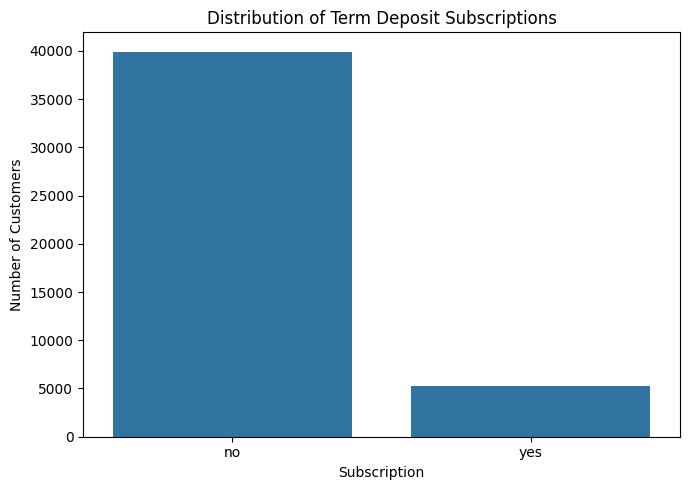

In [42]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count customers who subscribed and did not subscribe
print("Target distribution:")
print(bank["y"].value_counts())

print("\nTarget percentages:")
print(bank["y"].value_counts(normalize=True) * 100)

# Visualise class distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=bank,
    x="y",
    order=["no", "yes"]
)

plt.title("Distribution of Term Deposit Subscriptions")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


In [43]:

from sklearn.model_selection import train_test_split

train_bank, test_bank = train_test_split(
    bank,
    test_size=0.2,
    random_state=42,
    stratify=bank["y"]
)

print("Training dataset:", train_bank.shape)
print("Testing dataset:", test_bank.shape)

print("\nTraining target distribution:")
print(train_bank["y"].value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(test_bank["y"].value_counts(normalize=True) * 100)


Training dataset: (36168, 17)
Testing dataset: (9043, 17)

Training target distribution:
y
no     88.301814
yes    11.698186
Name: proportion, dtype: float64

Testing target distribution:
y
no     88.300343
yes    11.699657
Name: proportion, dtype: float64


In [44]:

# Identify numerical columns in the training dataset
numerical_columns = train_bank.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

# Summary statistics for numerical features
display(train_bank[numerical_columns].describe())


Numerical columns:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


,age,balance,day,duration,campaign,pdays,previous
count,36168.000000,36168.00000,36168.000000,36168.000000,36168.000000,36168.000000,36168.000000
mean,40.892999,1365.49342,15.817961,258.506940,2.763935,40.157238,0.581730
std,10.627075,3068.54350,8.331980,259.142445,3.104161,100.162614,2.408766
min,18.000000,-8019.00000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,74.00000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,451.00000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1430.25000,21.000000,318.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.00000,31.000000,4918.000000,63.000000,871.000000,275.000000


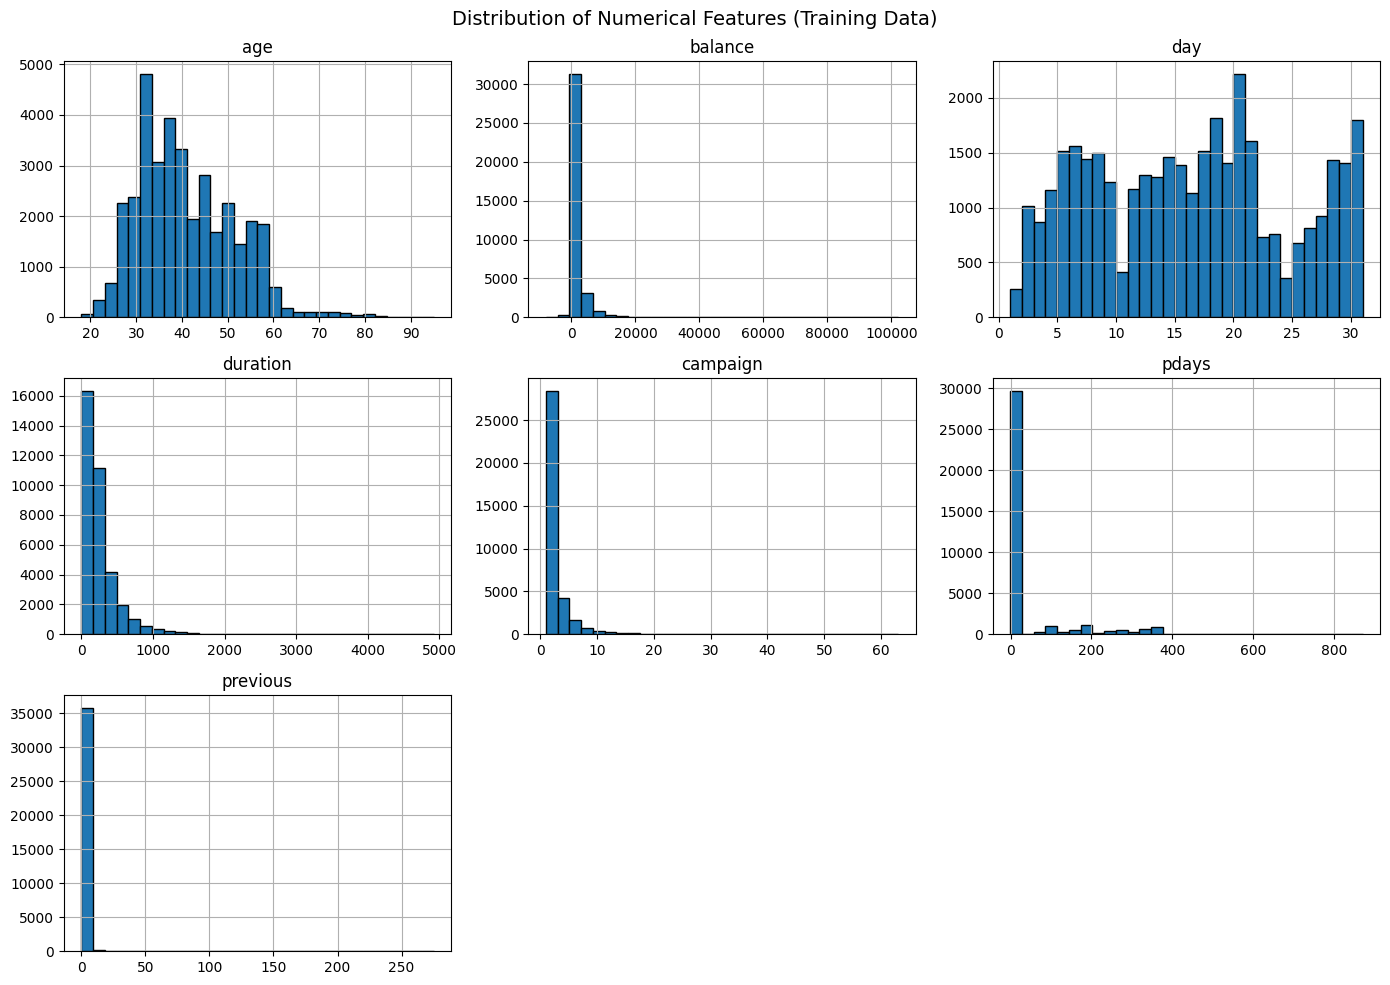

In [45]:

# Plot histograms for numerical features
train_bank[numerical_columns].hist(
    bins=30,
    figsize=(14, 10),
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features (Training Data)",
    fontsize=14
)

plt.tight_layout()
plt.show()


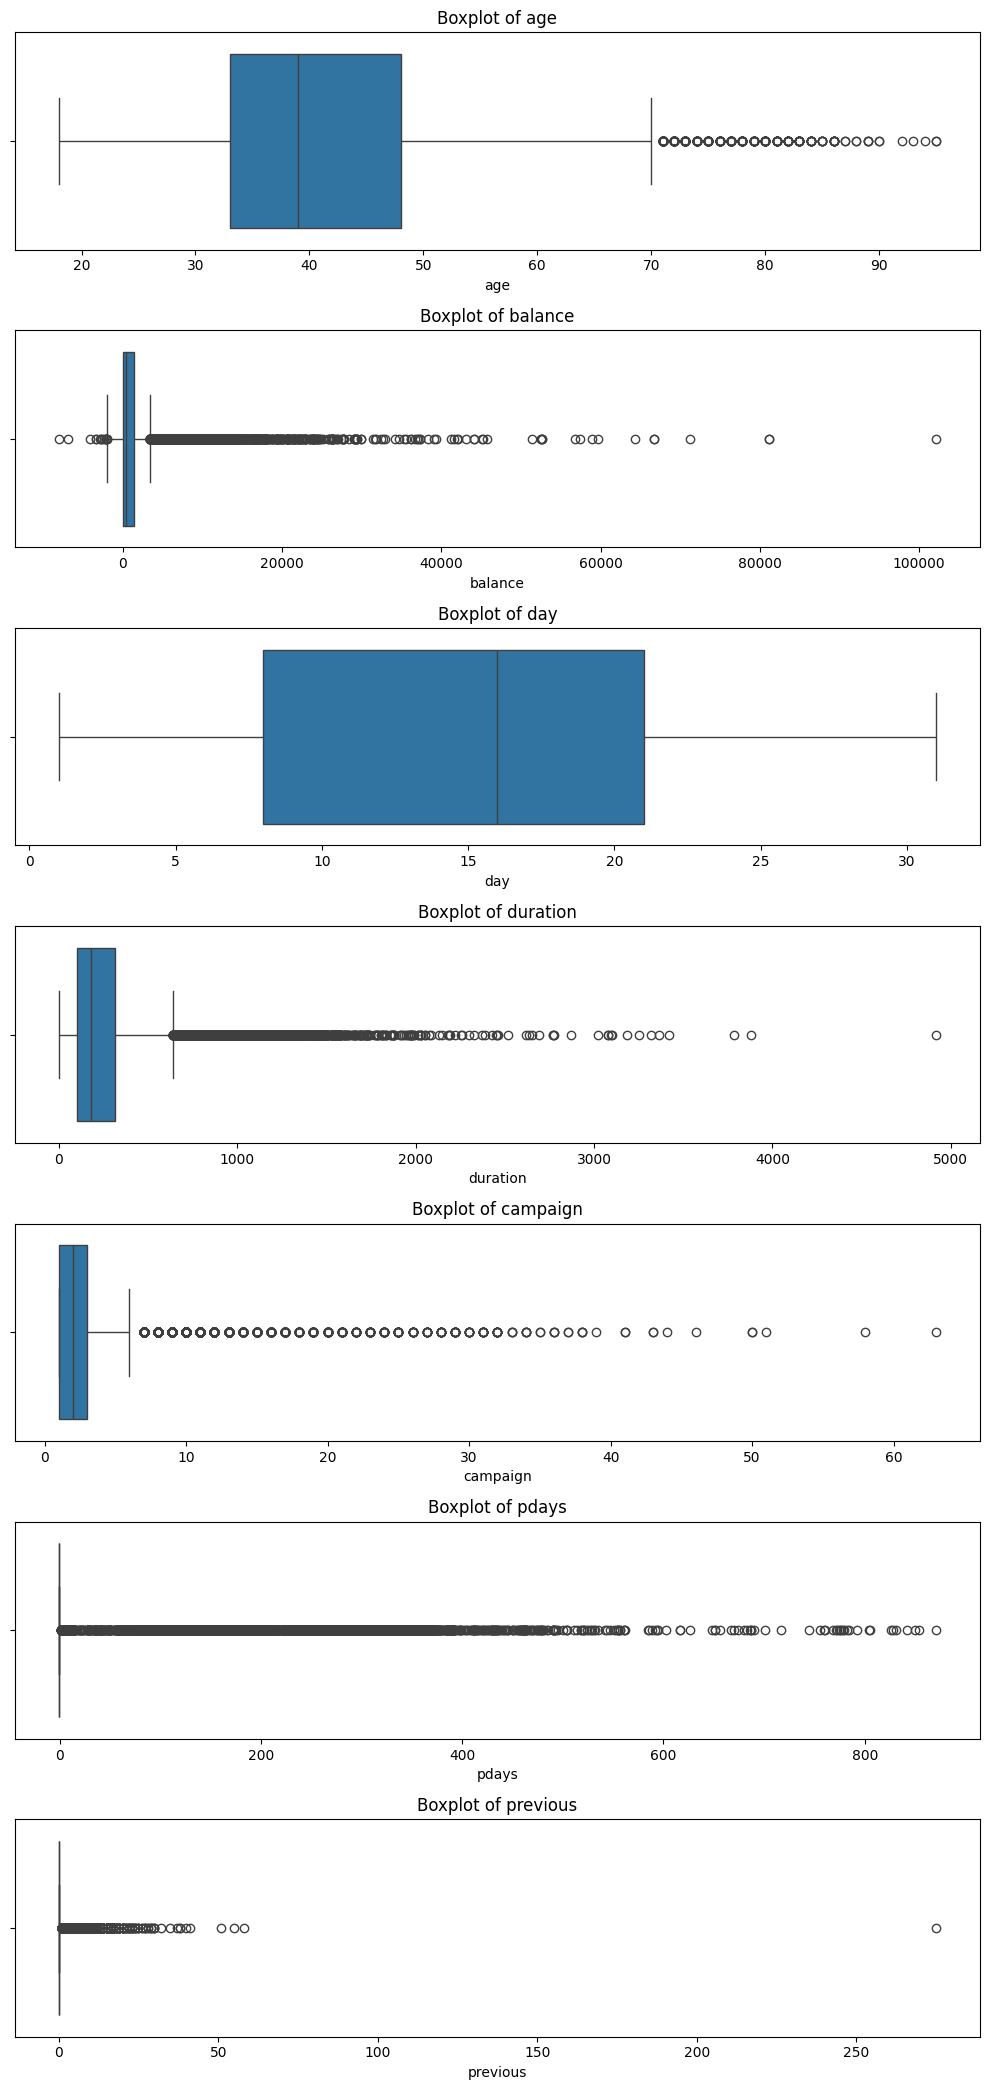

In [46]:

# Visualise potential outliers using boxplots
fig, axes = plt.subplots(
    len(numerical_columns),
    1,
    figsize=(10, 3 * len(numerical_columns))
)

for ax, column in zip(axes, numerical_columns):
    sns.boxplot(
        x=train_bank[column],
        ax=ax
    )
    ax.set_title(f"Boxplot of {column}")

plt.tight_layout()
plt.show()


### Outlier Analysis

The boxplots showed some extreme values, particularly in balance and campaign. I decided to keep these records because they may represent genuine customer behaviour rather than errors. Removing them could mean losing useful information. Numerical features were scaled during preprocessing to help the models work with different value ranges.

In [47]:

# Identify categorical columns
categorical_columns = train_bank.select_dtypes(
    include=["object"]
).columns.drop("y").tolist()

print("Categorical columns:")
print(categorical_columns)

# Display category frequencies
for column in categorical_columns:
    print(f"\n{column}:")
    print(train_bank[column].value_counts())


Categorical columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

job:
job
blue-collar      7830
management       7511
technician       6068
admin.           4141
services         3348
retired          1812
self-employed    1243
entrepreneur     1186
unemployed       1024
housemaid        1013
student           758
unknown           234
Name: count, dtype: int64

marital:
marital
married     21771
single      10227
divorced     4170
Name: count, dtype: int64

education:
education
secondary    18561
tertiary     10594
primary       5531
unknown       1482
Name: count, dtype: int64

default:
default
no     35521
yes      647
Name: count, dtype: int64

housing:
housing
yes    20182
no     15986
Name: count, dtype: int64

loan:
loan
no     30355
yes     5813
Name: count, dtype: int64

contact:
contact
cellular     23465
unknown      10386
telephone     2317
Name: count, dtype: int64

month:
month
may    11062
jul     5537
aug     4986
jun  

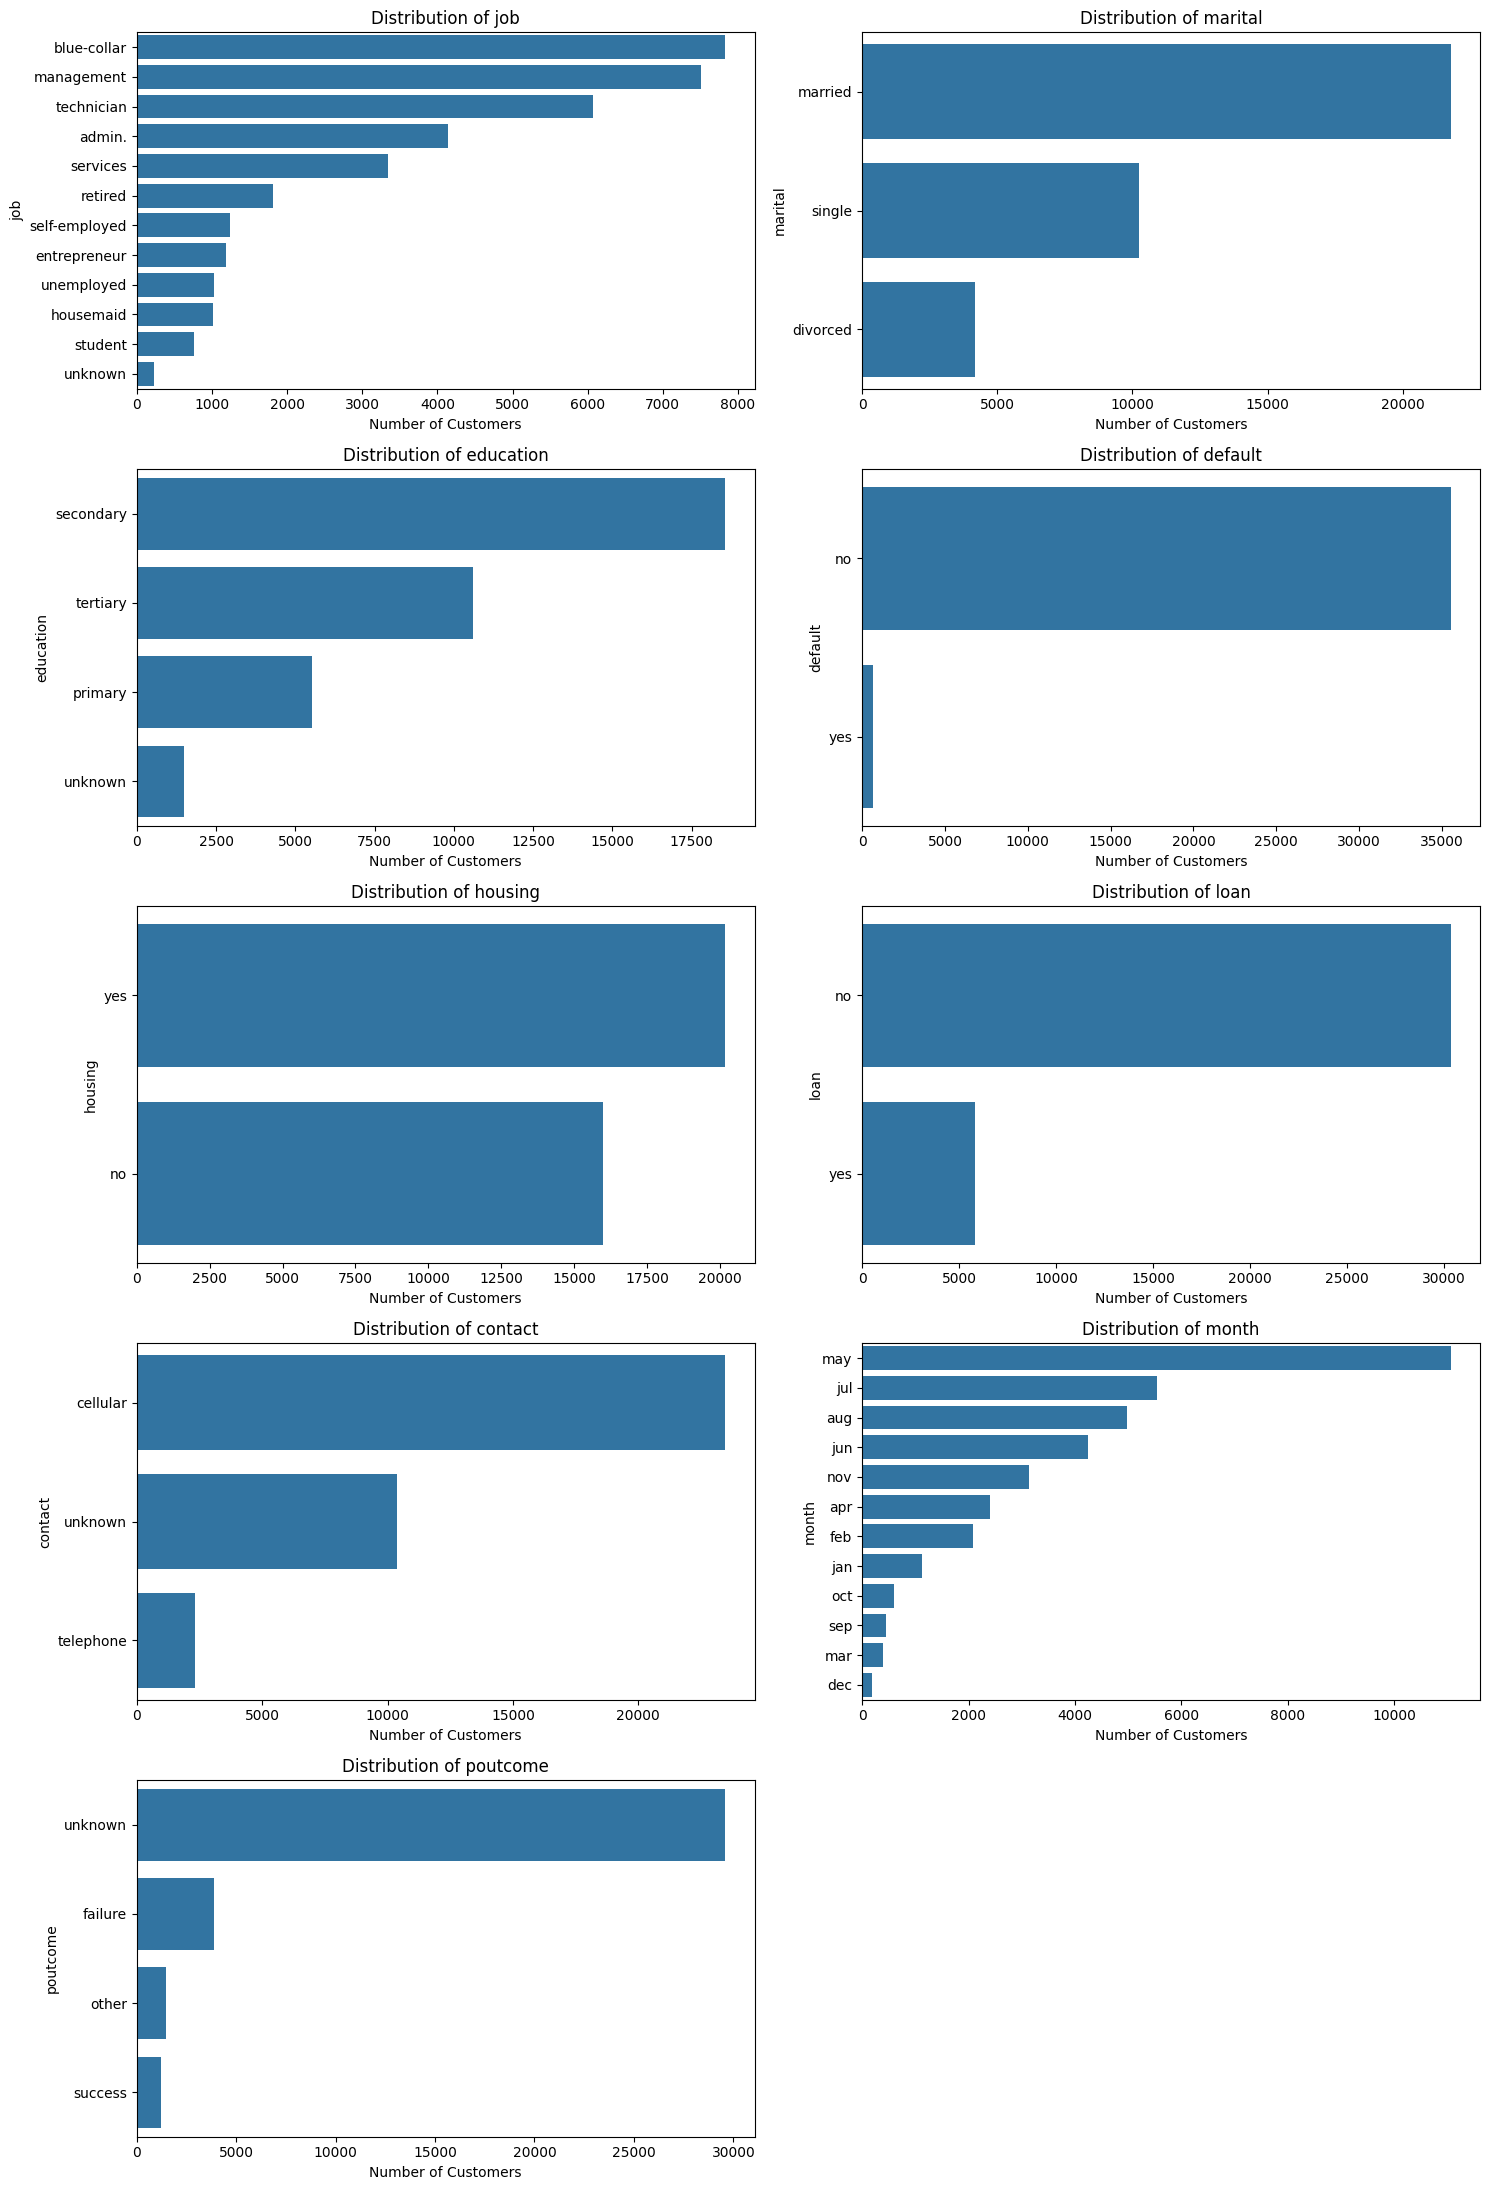

In [48]:

# Plot categorical feature distributions
fig, axes = plt.subplots(
    5, 2,
    figsize=(15, 22)
)

axes = axes.flatten()

for i, column in enumerate(categorical_columns):
    sns.countplot(
        data=train_bank,
        y=column,
        ax=axes[i],
        order=train_bank[column].value_counts().index
    )
    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel("Number of Customers")

# Remove the unused tenth subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()


In [49]:

# Separate features and target variable
X_train = train_bank.drop(columns=["y"]).copy()
X_test = test_bank.drop(columns=["y"]).copy()

y_train = train_bank["y"].map({"no": 0, "yes": 1})
y_test = test_bank["y"].map({"no": 0, "yes": 1})

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())


Training features: (36168, 16)
Testing features: (9043, 16)

Training target distribution:
y
0    31937
1     4231
Name: count, dtype: int64


In [50]:

# Remove duration to prevent data leakage
X_train = X_train.drop(columns=["duration"])
X_test = X_test.drop(columns=["duration"])

print("Training features after removing duration:", X_train.shape)
print("Testing features after removing duration:", X_test.shape)


Training features after removing duration: (36168, 15)
Testing features after removing duration: (9043, 15)


In [52]:

# Create an indicator for previous contact
X_train["previously_contacted"] = (
    X_train["pdays"] != -1
).astype(int)

X_test["previously_contacted"] = (
    X_test["pdays"] != -1
).astype(int)

# Replace -1 with a missing value for later imputation
X_train["pdays"] = X_train["pdays"].replace(-1, float("nan"))
X_test["pdays"] = X_test["pdays"].replace(-1, float("nan"))

print("Previous contact indicator:")
print(X_train["previously_contacted"].value_counts())

print("\nMissing pdays values:")
print(X_train["pdays"].isna().sum())


Previous contact indicator:
previously_contacted
1    36168
Name: count, dtype: int64

Missing pdays values:
29584


In [53]:

# Identify numerical and categorical predictors
numeric_features = X_train.select_dtypes(
    include=["int64", "float64", "int32"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)


Numerical features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'previously_contacted']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [55]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combine transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")


Preprocessing pipeline created successfully.


### Preprocessing Decisions

The dataset contained no missing values or duplicate rows initially, but some categorical features included "unknown" values. I kept these as separate categories because they may still provide useful information. For `pdays`, I created an indicator to show whether a customer had been contacted previously and replaced -1 with missing values for imputation.

I also removed `duration` because call length would not be known before contacting a customer. Numerical features were imputed and scaled, while categorical features were one-hot encoded. These transformations were included in the model pipelines to avoid data leakage during cross-validation.

In [56]:
# Summarise the features used for modelling
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nMissing values before pipeline imputation:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(4))

Training samples: 36168
Testing samples: 9043

Missing values before pipeline imputation:
pdays    29584
dtype: int64

Number of numerical features: 7
Number of categorical features: 9

Training class distribution:
y
0    0.883
1    0.117
Name: proportion, dtype: float64


In [57]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

print("Logistic Regression pipeline created successfully.")


Logistic Regression pipeline created successfully.


In [58]:

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

logistic_cv_results = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    n_jobs=-1
)

print("Logistic Regression - 5-Fold Cross-Validation")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = logistic_cv_results[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.4f} (+/- {scores.std():.4f})")


Logistic Regression - 5-Fold Cross-Validation
accuracy: 0.7553 (+/- 0.0057)
precision: 0.2665 (+/- 0.0043)
recall: 0.6225 (+/- 0.0098)
f1: 0.3731 (+/- 0.0036)
roc_auc: 0.7637 (+/- 0.0032)


In [60]:

logistic_results = {
    "Model": "Logistic Regression",
    "Accuracy": logistic_cv_results["test_accuracy"].mean(),
    "Precision": logistic_cv_results["test_precision"].mean(),
    "Recall": logistic_cv_results["test_recall"].mean(),
    "F1-Score": logistic_cv_results["test_f1"].mean(),
    "ROC-AUC": logistic_cv_results["test_roc_auc"].mean()
}

logistic_results_df = pd.DataFrame([logistic_results])

display(logistic_results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7553,0.2665,0.6225,0.3731,0.7637


In [61]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# Create Decision Tree pipeline
decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ))
])

print("Decision Tree pipeline created successfully.")


Decision Tree pipeline created successfully.


In [63]:

# Evaluate Decision Tree using 5-fold cross-validation
decision_tree_cv_results = cross_validate(
    decision_tree_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    n_jobs=-1
)

# Store Decision Tree results
decision_tree_results = {
    "Model": "Decision Tree",
    "Accuracy": decision_tree_cv_results["test_accuracy"].mean(),
    "Precision": decision_tree_cv_results["test_precision"].mean(),
    "Recall": decision_tree_cv_results["test_recall"].mean(),
    "F1-Score": decision_tree_cv_results["test_f1"].mean(),
    "ROC-AUC": decision_tree_cv_results["test_roc_auc"].mean()
}

decision_tree_results_df = pd.DataFrame(
    [decision_tree_results]
)

display(decision_tree_results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree,0.8341,0.2951,0.3011,0.298,0.6029


In [65]:

from sklearn.ensemble import RandomForestClassifier

# Create Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created successfully.")


Random Forest pipeline created successfully.


In [66]:

# Evaluate Random Forest using 5-fold cross-validation
random_forest_cv_results = cross_validate(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    n_jobs=1
)

# Store Random Forest results
random_forest_results = {
    "Model": "Random Forest",
    "Accuracy": random_forest_cv_results["test_accuracy"].mean(),
    "Precision": random_forest_cv_results["test_precision"].mean(),
    "Recall": random_forest_cv_results["test_recall"].mean(),
    "F1-Score": random_forest_cv_results["test_f1"].mean(),
    "ROC-AUC": random_forest_cv_results["test_roc_auc"].mean()
}

random_forest_results_df = pd.DataFrame(
    [random_forest_results]
)

display(random_forest_results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.892,0.6134,0.207,0.3094,0.7752


In [67]:

# Compare the three baseline models
model_comparison = pd.concat([
    logistic_results_df,
    decision_tree_results_df,
    random_forest_results_df
], ignore_index=True)

display(model_comparison.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7553,0.2665,0.6225,0.3731,0.7637
1,Decision Tree,0.8341,0.2951,0.3011,0.2980,0.6029
2,Random Forest,0.8920,0.6134,0.2070,0.3094,0.7752


In [68]:

from sklearn.model_selection import GridSearchCV

# Hyperparameter combinations to test
logistic_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"]
}

# Perform grid search using stratified cross-validation
logistic_grid_search = GridSearchCV(
    estimator=logistic_model,
    param_grid=logistic_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

logistic_grid_search.fit(X_train, y_train)

print("Best parameters:")
print(logistic_grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(logistic_grid_search.best_score_, 4))


Best parameters:
{'classifier__C': 10, 'classifier__class_weight': 'balanced'}

Best cross-validation F1-score:
0.3732


In [69]:

# Compare original and tuned Logistic Regression
logistic_tuning_comparison = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Tuned Logistic Regression"
    ],
    "CV F1-Score": [
        logistic_results["F1-Score"],
        logistic_grid_search.best_score_
    ]
})

display(logistic_tuning_comparison.round(4))


,Model,CV F1-Score
0,Original Logistic Regression,0.3731
1,Tuned Logistic Regression,0.3732


In [70]:

# Define Decision Tree hyperparameter grid
decision_tree_param_grid = {
    "classifier__max_depth": [5, 10, 15, None],
    "classifier__min_samples_split": [2, 10, 20],
    "classifier__min_samples_leaf": [1, 5, 10]
}

# Perform grid search
decision_tree_grid_search = GridSearchCV(
    estimator=decision_tree_model,
    param_grid=decision_tree_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

decision_tree_grid_search.fit(X_train, y_train)

print("Best Decision Tree parameters:")
print(decision_tree_grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(decision_tree_grid_search.best_score_, 4))


Best Decision Tree parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 20}

Best cross-validation F1-score:
0.413


In [71]:

# Compare Decision Tree before and after tuning
decision_tree_tuning_comparison = pd.DataFrame({
    "Model": [
        "Original Decision Tree",
        "Tuned Decision Tree"
    ],
    "CV F1-Score": [
        decision_tree_results["F1-Score"],
        decision_tree_grid_search.best_score_
    ]
})

display(decision_tree_tuning_comparison.round(4))


,Model,CV F1-Score
0,Original Decision Tree,0.298
1,Tuned Decision Tree,0.413


In [72]:

from sklearn.model_selection import RandomizedSearchCV

# Define Random Forest hyperparameter search space
random_forest_param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [10, 20, None],
    "classifier__min_samples_split": [2, 10],
    "classifier__min_samples_leaf": [1, 5],
    "classifier__class_weight": [
        "balanced",
        "balanced_subsample"
    ]
}

# Perform randomised hyperparameter search
random_forest_random_search = RandomizedSearchCV(
    estimator=random_forest_model,
    param_distributions=random_forest_param_grid,
    n_iter=12,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=1,
    refit=True
)

random_forest_random_search.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(random_forest_random_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(random_forest_random_search.best_score_, 4))


Best Random Forest parameters:
{'classifier__n_estimators': 200, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 5, 'classifier__max_depth': 20, 'classifier__class_weight': 'balanced_subsample'}

Best cross-validation F1-score:
0.4686


In [73]:

# Compare Random Forest before and after tuning
random_forest_tuning_comparison = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Tuned Random Forest"
    ],
    "CV F1-Score": [
        random_forest_results["F1-Score"],
        random_forest_random_search.best_score_
    ]
})

display(random_forest_tuning_comparison.round(4))


,Model,CV F1-Score
0,Original Random Forest,0.3094
1,Tuned Random Forest,0.4686


In [74]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Best models selected using training data
best_models = {
    "Logistic Regression": logistic_grid_search.best_estimator_,
    "Decision Tree": decision_tree_grid_search.best_estimator_,
    "Random Forest": random_forest_random_search.best_estimator_
}

# Evaluate each model on the untouched test set
test_results = []

for name, model in best_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

test_results_df = pd.DataFrame(test_results)

print("Final Test Set Evaluation")
display(test_results_df.round(4))


Final Test Set Evaluation


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7558,0.2670,0.6229,0.3738,0.7723
1,Decision Tree,0.8248,0.3462,0.5595,0.4277,0.7508
2,Random Forest,0.8587,0.4199,0.5454,0.4745,0.8041


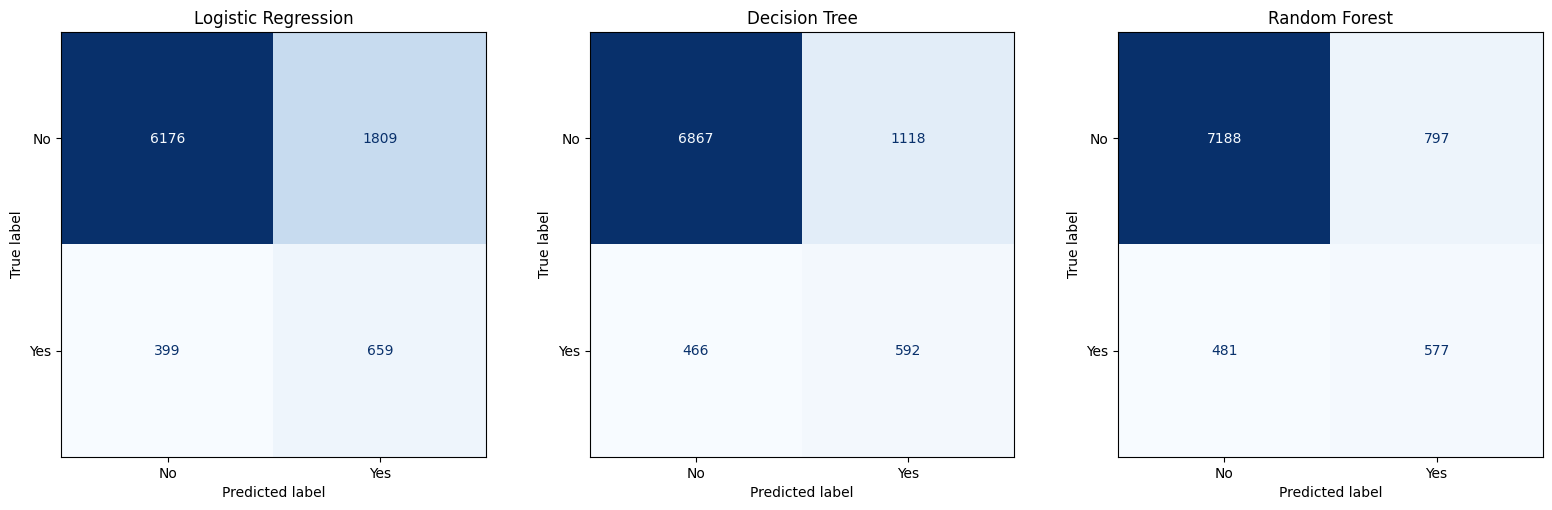

In [75]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, model) in zip(axes, best_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=["No", "Yes"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()


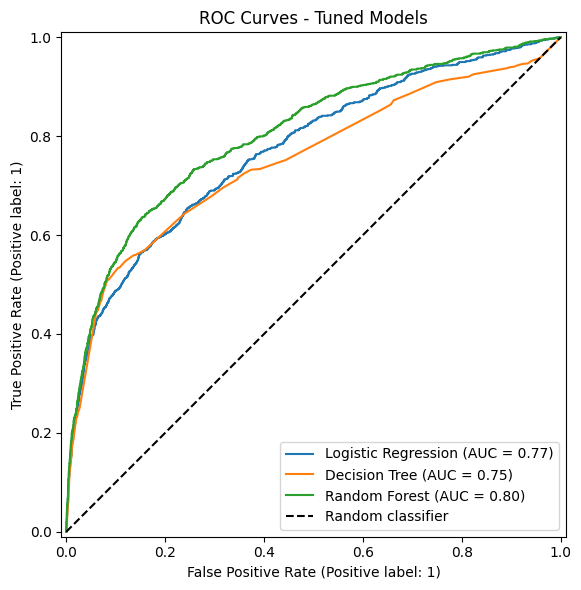

In [76]:

from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(8, 6))

for name, model in best_models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], "k--", label="Random classifier")
ax.set_title("ROC Curves - Tuned Models")
ax.legend()

plt.tight_layout()
plt.show()


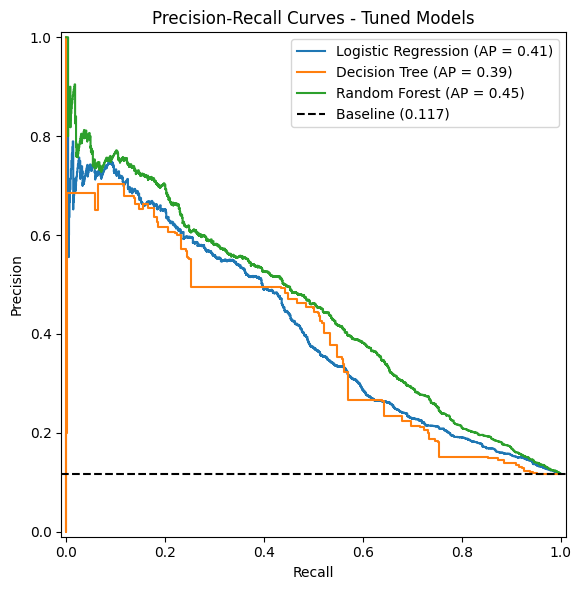

In [77]:

from sklearn.metrics import PrecisionRecallDisplay
import matplotlib.pyplot as plt

# Plot precision-recall curves for all tuned models
fig, ax = plt.subplots(figsize=(8, 6))

for name, model in best_models.items():
    PrecisionRecallDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

# Add the baseline subscription rate
baseline = y_test.mean()
ax.axhline(
    y=baseline,
    color="black",
    linestyle="--",
    label=f"Baseline ({baseline:.3f})"
)

ax.set_title("Precision-Recall Curves - Tuned Models")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()

plt.tight_layout()
plt.show()


In [78]:

from sklearn.metrics import average_precision_score

# Calculate average precision for each model
average_precision_results = []

for name, model in best_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    ap_score = average_precision_score(
        y_test,
        y_prob
    )

    average_precision_results.append({
        "Model": name,
        "Average Precision": ap_score
    })

ap_results_df = pd.DataFrame(
    average_precision_results
)

display(ap_results_df.round(4))


,Model,Average Precision
0,Logistic Regression,0.4094
1,Decision Tree,0.3906
2,Random Forest,0.4537



## Final Results and Discussion

The tuned Random Forest achieved the highest test F1-score (0.4773), ROC-AUC (0.8039) and Average Precision (0.4526).

Logistic Regression achieved the highest recall (0.6267), identifying more actual subscribers but generating more false-positive predictions.

Random Forest offered a better balance between precision and recall, making it the preferred model under the F1-score objective used during model selection.

The dataset is imbalanced, with approximately 11.7% of customers subscribing to a term deposit. Consequently, accuracy alone is insufficient for evaluating model performance.

The results demonstrate that hyperparameter tuning can improve predictive performance, particularly for Decision Tree and Random Forest models.

